# Analytics Vidhya — классификация по CSV

Метки читаются из `train/train/train.csv`, фото — из соседней папки `images/`. В `test/test/test.csv` класс не указан.

Локальные файлы содержат числовые классы `1…6` без расшифровки. По умолчанию показываются исходные номера. Словарь `LABEL_NAMES` можно заполнить при наличии проверенного описания классов. `sample_submission-3.csv` — пример формата предсказаний, а не разметка тестовых фото. Пространственной разметки в CSV нет: класс подписывается над всем изображением.

`SPLIT`: `train`, `test`, `all`. Пример фильтра: `CLASS_FILTER = "2"`.

Запустите ячейки сверху вниз. **Для новой случайной подборки повторите последнюю ячейку.** Настройки: количество фото, выборка, фильтр класса, случайное зерно, контуры, рамки и подписи. Исходные поля выбранной записи: `selected_samples[0]["metadata"]`.


In [1]:
import csv
import json
import sys
from pathlib import Path

current_dir = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in [current_dir, *current_dir.parents] if (path / "datasets").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Откройте ноутбук из папки проекта с каталогом datasets/.")
VIEWERS_DIR = PROJECT_ROOT / "code" / "viewers"
if str(VIEWERS_DIR) not in sys.path:
    sys.path.insert(0, str(VIEWERS_DIR))

from viewer_common import (
    IMAGE_SUFFIXES, image_files, load_coco, load_supervisely,
    read_jsonl, show_samples, summarize,
)


In [2]:
DATASET_ROOT = PROJECT_ROOT / "datasets" / "analytics_vidya"
SPLIT = "train"
LABEL_NAMES = {}             # {1: "проверенное название класса", ...}
N_IMAGES = 6
N_COLS = 3
SEED = None                 # Целое число фиксирует подборку
CLASS_FILTER = None         # Название класса или список; None = все
SHOW_MASKS = True
SHOW_BOXES = True
SHOW_LABELS = True
SHOW_CLASS_IDS = False
ONLY_ANNOTATED = False


In [3]:
def load_dataset(root):
    samples = []
    for split_name in ("train", "test"):
        folder = root / split_name / split_name
        with (folder / f"{split_name}.csv").open(encoding="utf-8-sig", newline="") as stream:
            for row in csv.DictReader(stream):
                class_id = int(row["label"]) if row.get("label") else None
                label = LABEL_NAMES.get(class_id, str(class_id)) if class_id is not None else None
                samples.append({
                    "image_path": folder / "images" / row["filename"],
                    "file_name": row["filename"], "split": split_name,
                    "label": label, "class_id": class_id, "annotations": [],
                    "metadata": row, "task": "classification",
                })
    return samples

dataset = load_dataset(DATASET_ROOT)
summary = summarize(dataset)


Записей: 12,000; изображения отсутствуют: 0
Выборки: {'train': 7200, 'test': 4800}
Классы (число меток):
  1: 171
  2: 2,349
  3: 534
  4: 2,079
  5: 1,185
  6: 882


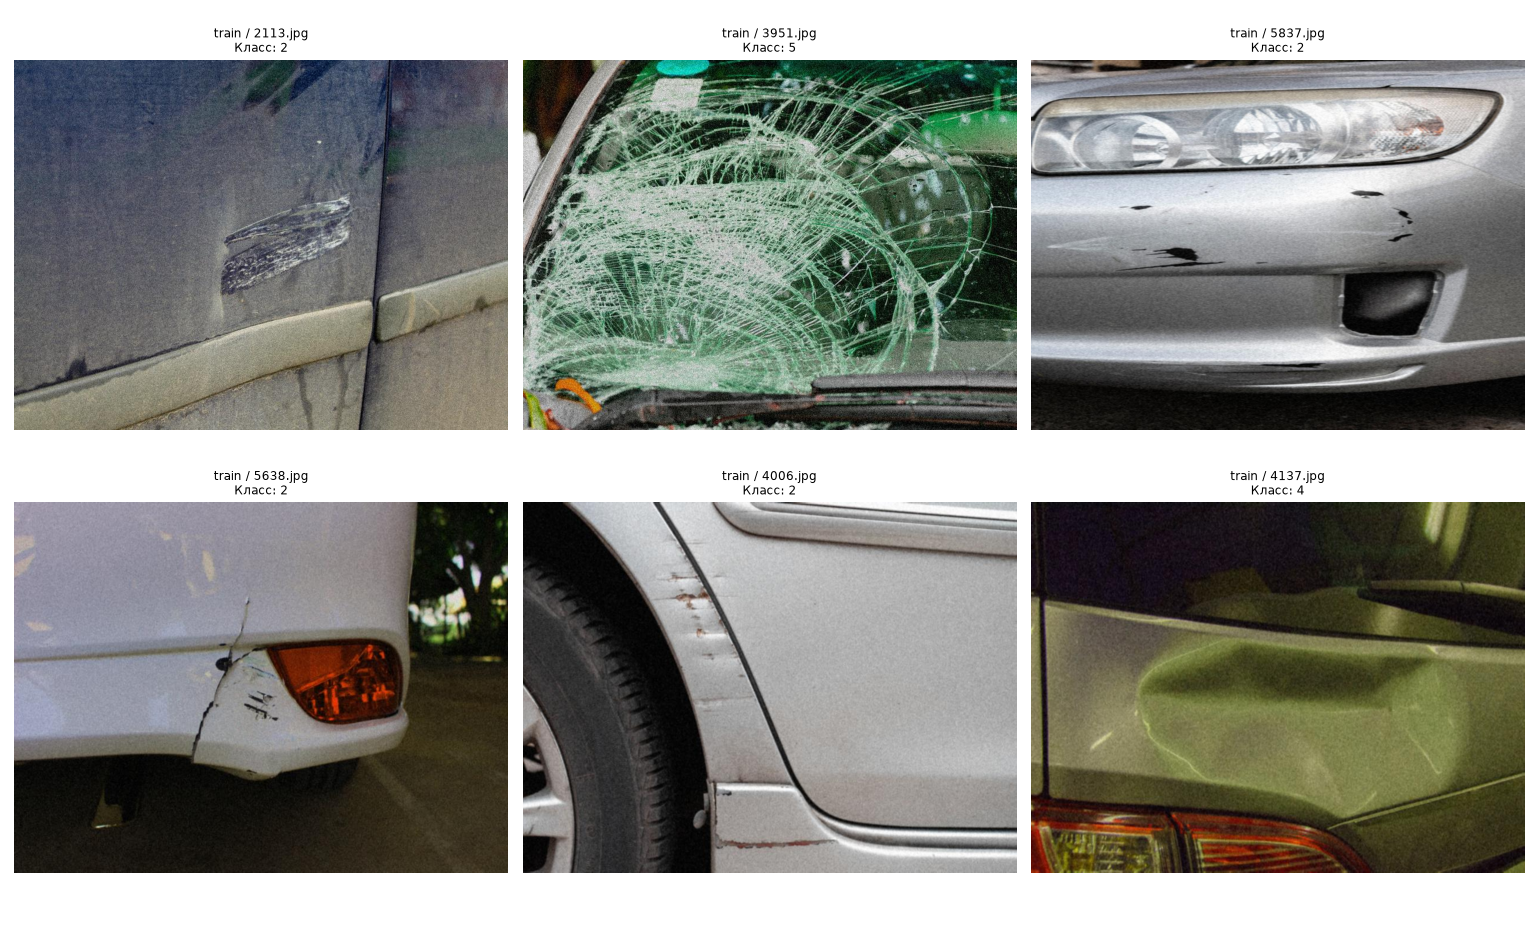

In [4]:
# Повторный запуск этой ячейки показывает новую случайную подборку.
figure, selected_samples = show_samples(
    dataset, n_images=N_IMAGES, n_cols=N_COLS, seed=SEED,
    split=SPLIT, class_filter=CLASS_FILTER,
    show_masks=SHOW_MASKS, show_boxes=SHOW_BOXES,
    show_labels=SHOW_LABELS, show_class_ids=SHOW_CLASS_IDS,
    only_annotated=ONLY_ANNOTATED,
)
